In [ ]:
# 0.1. Mount Google Drive for persistent storage (optional but recommended)
from google.colab import drive
drive.mount('/content/drive')

# Define a project path in your Google Drive
project_path = '/content/drive/MyDrive/DataLeakMonitorProject'
import os
if not os.path.exists(project_path):
    os.makedirs(project_path)
    print(f"Created project directory: {project_path}")
else:
    print(f"Project directory already exists: {project_path}")

# 0.2. Install necessary libraries
# spaCy for NER and advanced NLP
# scikit-learn for machine learning models
# pandas for data handling
# requests (if you plan to hit real APIs, though we'll simulate for now)
!pip install spacy pandas scikit-learn matplotlib seaborn faker

# Download spaCy English model
!python -m spacy download en_core_web_sm

print("\n--- Setup Complete ---")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory already exists: /content/drive/MyDrive/DataLeakMonitorProject
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 73.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.

--- Setup Complete ---


In [ ]:
import pandas as pd
from faker import Faker
import random

# Initialize Faker for generating fake data
fake = Faker('en_US') # Use US locale for relevant PII patterns

def generate_social_media_post(is_leak=False):
    """Generates a synthetic social media post, optionally including 'leak' data."""
    post_templates = [
        "Just enjoying a sunny day! #goodvibes",
        "Had a great coffee this morning.",
        "Thinking about new tech trends. #AI #future",
        "My favorite movie is [Movie Title]. What's yours?",
        "Look at this beautiful scenery! 🏞️",
        "Checking out the new update for [App Name].",
        "A little rain never hurt anyone.",
        "Learning something new every day.",
        "Big news coming soon!",
        "Feeling refreshed after a long walk."
    ]

    leak_patterns = [
        f"Oops, left my password for our staging server as: {fake.password()} in a public doc.",
        f"Found a list of emails: {fake.email()}, {fake.email()}, {fake.email()} and some credit card numbers: {fake.credit_card_number()}.",
        f"Heads up! Our internal API key is `AKIAIOSFODNN7EXAMPLE_2345` on this forum.",
        f"My old email for support is {fake.email()}, contact me there. And my phone is {fake.phone_number()}.",
        f"Employee credentials leaked: user@company.com:{fake.password()}",
        f"Confidential document link: https://docs.google.com/document/d/EXAMPLE_CONFIDENTIAL_DOC",
        f"Database dump found here: s3://my-company-bucket/backup-2023-11.zip"
    ]

    if is_leak:
        # Mix in some normal text with a leak pattern to make it more realistic
        normal_text = random.choice(post_templates)
        leak_text = random.choice(leak_patterns)
        # Randomly decide to put leak at beginning or end or middle
        if random.random() < 0.33:
            return f"{leak_text} {normal_text}"
        elif random.random() < 0.66:
            return f"{normal_text} {leak_text}"
        else:
            return f"{normal_text.split('.')[0]} {leak_text} {normal_text.split('.')[-1]}"
    else:
        return random.choice(post_templates)

# Generate a synthetic dataset
num_posts = 1000
num_leaks = 50 # Let's inject 50 fake leaks
data = []

for _ in range(num_posts - num_leaks):
    data.append({'post': generate_social_media_post(is_leak=False), 'is_leak': 0})

for _ in range(num_leaks):
    data.append({'post': generate_social_media_post(is_leak=True), 'is_leak': 1})

# Shuffle the data
random.shuffle(data)
df = pd.DataFrame(data)

print(f"Generated {len(df)} posts. {df['is_leak'].sum()} simulated leaks.")
print("\nSample Data:")
print(df.head())

# Save the raw data
df.to_csv(os.path.join(project_path, 'synthetic_social_media_data.csv'), index=False)
print(f"\nData saved to {os.path.join(project_path, 'synthetic_social_media_data.csv')}")

Generated 1000 posts. 50 simulated leaks.

Sample Data:
                                                post  is_leak
0                   Had a great coffee this morning.        0
1                  Learning something new every day.        0
2  My favorite movie is [Movie Title]. What's yours?        0
3                  Learning something new every day.        0
4        Checking out the new update for [App Name].        0

Data saved to /content/drive/MyDrive/DataLeakMonitorProject/synthetic_social_media_data.csv


In [ ]:
import re
import spacy

# Load the small English spaCy model
nlp = spacy.load("en_core_web_sm")

def preprocess_text(text):
    """
    Cleans and preprocesses text:
    - Lowercasing
    - Removing URLs (optional, might want to keep for leak detection)
    - Removing special characters (keep some like @, # if relevant)
    - Lemmatization (optional, but good for ML classification)
    """
    text = text.lower()
    # Remove URLs - can be adjusted if URLs themselves are part of leak detection
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Remove some common special characters, but keep alphanumeric, spaces, and few symbols
    text = re.sub(r'[^a-zA-Z0-9\s@#.-]', '', text)
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Lemmatization using spaCy
    doc = nlp(text)
    lemmas = [token.lemma_ for token in doc if not token.is_stop and not token.is_punct]
    return " ".join(lemmas)

# Apply preprocessing
df['cleaned_post'] = df['post'].apply(preprocess_text)

print("\n--- Preprocessing Sample ---")
print(df[['post', 'cleaned_post']].head())

# Save preprocessed data
df.to_csv(os.path.join(project_path, 'preprocessed_social_media_data.csv'), index=False)


--- Preprocessing Sample ---
                                                post  \
0                   Had a great coffee this morning.   
1                  Learning something new every day.   
2  My favorite movie is [Movie Title]. What's yours?   
3                  Learning something new every day.   
4        Checking out the new update for [App Name].   

                   cleaned_post  
0          great coffee morning  
1                 learn new day  
2  favorite movie movie title s  
3                 learn new day  
4          check new update app  


In [ ]:
import re

def detect_pii_regex(text):
    """Detects common PII patterns using regular expressions."""
    findings = []

    # Email addresses
    email_pattern = r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}'
    emails = re.findall(email_pattern, text)
    if emails:
        findings.append(f"Email Addresses: {', '.join(emails)}")

    # Phone numbers (simple US pattern, can be expanded)
    phone_pattern = r'(\d{3}[-\.\s]??\d{3}[-\.\s]??\d{4}|\(\d{3}\)\s*\d{3}[-\.\s]??\d{4}|\d{10})'
    phones = re.findall(phone_pattern, text)
    if phones:
        findings.append(f"Phone Numbers: {', '.join(phones)}")

    # Credit Card Numbers (simplified, usually requires Luhn algorithm for validation)
    # This pattern is broad and will catch many 16-digit numbers. For production, add Luhn check.
    cc_pattern = r'\b(?:\d[ -]*?){13,16}\b'
    ccs = re.findall(cc_pattern, text)
    if ccs:
        findings.append(f"Credit Card Numbers: {', '.join(ccs)}")

    # IP Addresses
    ip_pattern = r'\b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b'
    ips = re.findall(ip_pattern, text)
    if ips:
        findings.append(f"IP Addresses: {', '.join(ips)}")

    # API Keys (example - needs specific patterns for different services)
    # This is a very generic example. Real API keys have specific formats.
    api_key_pattern = r'\b(AKIA|SG|pk|sk)[a-zA-Z0-9]{16,40}\b|\b([A-Fa-f0-9]{32,64})\b' # Example for AWS-like and generic hex
    api_keys = re.findall(api_key_pattern, text)
    # Flatten the list of tuples for api_keys
    flat_api_keys = [item for sublist in api_keys for item in sublist if item]
    if flat_api_keys:
        findings.append(f"Potential API Keys: {', '.join(flat_api_keys)}")

    # Generic passwords (very difficult to define reliably with regex without high false positives)
    # A simple example: looking for "password:" followed by some alphanumeric characters
    password_pattern = r'(password|pass|passwd|pwd):\s*([a-zA-Z0-9!@#$%^&*()_+]{6,30})'
    passwords = re.findall(password_pattern, text)
    if passwords:
        # Passwords found in group 2 of the regex match
        found_passwords = [p[1] for p in passwords]
        findings.append(f"Potential Passwords: {', '.join(found_passwords)}")

    # Confidential Document Links (generic example)
    doc_link_pattern = r'https?://docs\.google\.com/document/d/[a-zA-Z0-9_-]+|s3://[a-zA-Z0-9_.-]+/.*\.zip'
    doc_links = re.findall(doc_link_pattern, text)
    if doc_links:
        findings.append(f"Confidential Document Links: {', '.join(doc_links)}")


    return findings if findings else None

# Apply PII detection
df['regex_findings'] = df['post'].apply(detect_pii_regex)
df['has_regex_leak'] = df['regex_findings'].apply(lambda x: 1 if x else 0)

print("\n--- Regex PII Detection Sample ---")
# Display posts where regex found something
print(df[df['has_regex_leak'] == 1][['post', 'regex_findings']].head(10))

print(f"\nTotal posts with regex-detected leaks: {df['has_regex_leak'].sum()}")


--- Regex PII Detection Sample ---
                                                  post  \
7    Checking out the new update for [App Name]. Da...   
47   Found a list of emails: blacksharon@example.co...   
54   Learning something new every day Found a list ...   
58   Confidential document link: https://docs.googl...   
126  Just enjoying a sunny day! #goodvibes My old e...   
143  Database dump found here: s3://my-company-buck...   
145  Confidential document link: https://docs.googl...   
188  Just enjoying a sunny day! #goodvibes Confiden...   
204  A little rain never hurt anyone. Confidential ...   
209  Feeling refreshed after a long walk. Found a l...   

                                        regex_findings  
7    [Confidential Document Links: s3://my-company-...  
47   [Email Addresses: blacksharon@example.com, bla...  
54   [Email Addresses: keith30@example.com, huberki...  
58   [Confidential Document Links: https://docs.goo...  
126  [Email Addresses: briana26@example.

In [ ]:
import spacy

# Load the small English spaCy model (already loaded in preprocessing, but good to ensure)
# nlp = spacy.load("en_core_web_sm") # Uncomment if you restart runtime and skipped earlier load

def detect_sensitive_entities(text):
    """Detects PERSON, ORG, GPE entities using spaCy NER."""
    doc = nlp(text)
    entities = []
    for ent in doc.ents:
        if ent.label_ in ["PERSON", "ORG", "GPE", "LOC", "PRODUCT", "EVENT"]: # Expanded list
            entities.append(f"{ent.text} ({ent.label_})")
    return entities if entities else None

# Apply NER detection
df['ner_findings'] = df['post'].apply(detect_sensitive_entities)
df['has_ner_entity'] = df['ner_findings'].apply(lambda x: 1 if x else 0)


print("\n--- NER Detection Sample ---")
# Display posts where NER found something interesting
print(df[df['has_ner_entity'] == 1][['post', 'ner_findings']].head(10))

print(f"\nTotal posts with NER-detected entities: {df['has_ner_entity'].sum()}")


--- NER Detection Sample ---
                                                 post  \
2   My favorite movie is [Movie Title]. What's yours?   
18  My favorite movie is [Movie Title]. What's yours?   
42  My favorite movie is [Movie Title]. What's yours?   
49  My favorite movie is [Movie Title]. What's yours?   
50  My favorite movie is [Movie Title]. What's yours?   
54  Learning something new every day Found a list ...   
59  My favorite movie is [Movie Title]. What's yours?   
64  My favorite movie is [Movie Title]. What's yours?   
67  My favorite movie is [Movie Title]. What's yours?   
73  My favorite movie is [Movie Title]. What's yours?   

                      ner_findings  
2              [Movie Title (ORG)]  
18             [Movie Title (ORG)]  
42             [Movie Title (ORG)]  
49             [Movie Title (ORG)]  
50             [Movie Title (ORG)]  
54  [keith30@example.com (PERSON)]  
59             [Movie Title (ORG)]  
64             [Movie Title (ORG)]  
67       

In [ ]:
!pip install transformers

from transformers import pipeline

# Load a ready sentiment/classification pipeline (change to leak-targeted model if you fine-tune one!)
leak_classifier = pipeline("text-classification", model="distilbert-base-uncased-finetuned-sst-2-english")

def get_leak_score_transformer(text):
    result = leak_classifier(text)[0]
    # Optionally: map "NEGATIVE"/"POSITIVE" to "leak"/"safe" if you fine-tune
    return result['label'], result['score']

# Use this in your analysis function:
def analyze_post_for_leak(post_text):
    # ... previous logic ...
    label, score = get_leak_score_transformer(post_text)
    results['details']['transformer_prediction'] = label
    results['details']['transformer_score'] = float(score)
    if label == "NEGATIVE" and score > 0.80: # adjust label threshold as needed
        results["is_leak_detected"] = True
        results["detection_methods"].append(f"Transformer NLP ({score:.2f})")
    # ... rest of your logic ...
    return results


Device set to use cpu


In [ ]:
!pip install pycryptodome

from Crypto.PublicKey import RSA
from Crypto.Cipher import PKCS1_OAEP, AES
from Crypto.Random import get_random_bytes

# Generate and save keys ONCE before running analysis (setup stage)
key = RSA.generate(2048)
private_key = key.export_key()
public_key = key.publickey().export_key()
with open(project_path + '/private.pem', 'wb') as p: p.write(private_key)
with open(project_path + '/public.pem', 'wb') as p: p.write(public_key)

# Encryption function for alerts
def encrypt_alert_message(message, public_key_file):
    session_key = get_random_bytes(16)
    cipher_rsa = PKCS1_OAEP.new(RSA.import_key(open(public_key_file).read()))
    encrypted_session_key = cipher_rsa.encrypt(session_key)
    cipher_aes = AES.new(session_key, AES.MODE_EAX)
    ciphertext, tag = cipher_aes.encrypt_and_digest(message.encode())
    return encrypted_session_key, cipher_aes.nonce, tag, ciphertext

# Example use in send_alert:
def send_alert(alert_info):
    alert_msg = str(alert_info)
    encrypted_session_key, nonce, tag, ciphertext = encrypt_alert_message(
        alert_msg, project_path + '/public.pem'
    )
    # Save or transmit the encrypted alert data; for demo:
    with open(project_path + '/latest_encrypted_alert.bin', 'wb') as f:
        f.write(encrypted_session_key + nonce + tag + ciphertext)
    print("--- Alert encrypted and saved securely ---")


In [ ]:
!pip install pycryptodome

import json
import hashlib
from datetime import datetime
from Crypto.PublicKey import RSA
from Crypto.Cipher import PKCS1_OAEP, AES
from Crypto.Random import get_random_bytes
from Crypto.Signature import pkcs1_15
from Crypto.Hash import SHA256
import base64

# ============================================
# 1. KEY GENERATION (One-time setup)
# ============================================
def generate_keys():
    """Generate RSA key pair and save to files"""
    print("🔑 Generating RSA Key Pair (2048-bit)...")
    key = RSA.generate(2048)
    private_key = key.export_key()
    public_key = key.publickey().export_key()

    # Save keys
    with open(project_path + '/private.pem', 'wb') as p:
        p.write(private_key)
    with open(project_path + '/public.pem', 'wb') as p:
        p.write(public_key)

    print("✅ Keys generated and saved successfully!")
    print(f"   Private Key: {project_path}/private.pem")
    print(f"   Public Key: {project_path}/public.pem")
    return private_key, public_key

# Generate keys
private_key, public_key = generate_keys()

# ============================================
# 2. ENHANCED ENCRYPTION FUNCTION
# ============================================
def encrypt_alert_message(alert_data, public_key_file):
    """
    Encrypts alert message using hybrid RSA + AES encryption
    Returns encrypted data with SHA-256 hash for integrity verification
    """
    # Convert alert data to JSON string
    message = json.dumps(alert_data, indent=2)

    # 1. Generate SHA-256 hash of original message (for integrity check)
    message_hash = hashlib.sha256(message.encode()).hexdigest()

    # 2. Generate random AES session key (256-bit for stronger security)
    session_key = get_random_bytes(32)  # 256-bit key

    # 3. Encrypt session key with RSA public key
    rsa_key = RSA.import_key(open(public_key_file).read())
    cipher_rsa = PKCS1_OAEP.new(rsa_key)
    encrypted_session_key = cipher_rsa.encrypt(session_key)

    # 4. Encrypt message with AES using the session key
    cipher_aes = AES.new(session_key, AES.MODE_EAX)
    ciphertext, tag = cipher_aes.encrypt_and_digest(message.encode())

    # 5. Create encryption metadata
    encryption_info = {
        'timestamp': datetime.now().isoformat(),
        'algorithm': 'RSA-2048 + AES-256',
        'mode': 'EAX',
        'message_hash_sha256': message_hash,
        'encrypted_session_key_length': len(encrypted_session_key),
        'ciphertext_length': len(ciphertext)
    }

    return {
        'encrypted_session_key': encrypted_session_key,
        'nonce': cipher_aes.nonce,
        'tag': tag,
        'ciphertext': ciphertext,
        'message_hash': message_hash,
        'encryption_info': encryption_info
    }

# ============================================
# 3. DECRYPTION FUNCTION
# ============================================
def decrypt_alert_message(encrypted_data, private_key_file):
    """
    Decrypts alert message using private RSA key
    Verifies integrity using SHA-256 hash
    """
    # 1. Decrypt session key with RSA private key
    rsa_key = RSA.import_key(open(private_key_file).read())
    cipher_rsa = PKCS1_OAEP.new(rsa_key)
    session_key = cipher_rsa.decrypt(encrypted_data['encrypted_session_key'])

    # 2. Decrypt message with AES using the session key
    cipher_aes = AES.new(session_key, AES.MODE_EAX, nonce=encrypted_data['nonce'])
    decrypted_message = cipher_aes.decrypt_and_verify(
        encrypted_data['ciphertext'],
        encrypted_data['tag']
    )

    # 3. Verify message integrity with SHA-256 hash
    decrypted_text = decrypted_message.decode()
    computed_hash = hashlib.sha256(decrypted_text.encode()).hexdigest()

    if computed_hash == encrypted_data['message_hash']:
        print("✅ Message integrity verified!")
    else:
        print("⚠️ Warning: Message hash mismatch! Data may be corrupted.")

    return json.loads(decrypted_text)

# ============================================
# 4. ENHANCED ALERT GENERATION
# ============================================
def generate_alert_data(leak_detection_result):
    """Generate structured alert data from leak detection"""
    alert_data = {
        'alert_id': hashlib.sha256(str(datetime.now()).encode()).hexdigest()[:16],
        'timestamp': datetime.now().isoformat(),
        'severity': 'CRITICAL' if 'password' in str(leak_detection_result) or 'api' in str(leak_detection_result).lower() else 'HIGH',
        'leak_detected': leak_detection_result.get('is_leak_detected', False),
        'detection_methods': leak_detection_result.get('detection_methods', []),
        'original_post': leak_detection_result.get('original_post', ''),
        'findings': {
            'regex': leak_detection_result.get('details', {}).get('regex_findings', []),
            'ner': leak_detection_result.get('details', {}).get('ner_findings', []),
            'ml_score': leak_detection_result.get('details', {}).get('ml_prediction_score', 0)
        },
        'action_required': 'IMMEDIATE INVESTIGATION REQUIRED',
        'recommended_actions': [
            'Remove the post immediately',
            'Contact the user',
            'Assess data exposure impact',
            'Report to security team'
        ]
    }
    return alert_data

# ============================================
# 5. ENHANCED SEND ALERT FUNCTION
# ============================================
def send_alert(leak_detection_result):
    """
    Enhanced alert system with encryption, hashing, and clear output
    """
    print("\n" + "="*70)
    print("🚨 DATA LEAK ALERT TRIGGERED 🚨")
    print("="*70)

    # 1. Generate structured alert data
    alert_data = generate_alert_data(leak_detection_result)

    # 2. Display original alert (before encryption)
    print("\n📋 ORIGINAL ALERT DATA:")
    print(json.dumps(alert_data, indent=2))

    # 3. Generate SHA-256 hash of original data
    original_hash = hashlib.sha256(json.dumps(alert_data).encode()).hexdigest()
    print(f"\n🔐 SHA-256 HASH (Original Data):")
    print(f"   {original_hash}")

    # 4. Encrypt the alert
    print("\n🔒 ENCRYPTING ALERT...")
    encrypted_data = encrypt_alert_message(alert_data, project_path + '/public.pem')

    # 5. Display encryption information
    print("\n✅ ENCRYPTION COMPLETE!")
    print("\n📊 ENCRYPTION DETAILS:")
    print(json.dumps(encrypted_data['encryption_info'], indent=2))

    # 6. Display encrypted components (Base64 encoded for readability)
    print("\n🔑 ENCRYPTED SESSION KEY (Base64):")
    print(base64.b64encode(encrypted_data['encrypted_session_key']).decode()[:100] + "...")

    print("\n🔐 ENCRYPTED MESSAGE (Base64):")
    print(base64.b64encode(encrypted_data['ciphertext']).decode()[:100] + "...")

    print("\n📝 AES NONCE (Base64):")
    print(base64.b64encode(encrypted_data['nonce']).decode())

    print("\n🏷️ AUTHENTICATION TAG (Base64):")
    print(base64.b64encode(encrypted_data['tag']).decode())

    # 7. Save encrypted alert to file
    alert_file = project_path + f'/encrypted_alert_{alert_data["alert_id"]}.bin'
    with open(alert_file, 'wb') as f:
        f.write(encrypted_data['encrypted_session_key'])
        f.write(encrypted_data['nonce'])
        f.write(encrypted_data['tag'])
        f.write(encrypted_data['ciphertext'])

    print(f"\n💾 Encrypted alert saved to: {alert_file}")

    # 8. Also save metadata as JSON
    metadata_file = project_path + f'/alert_metadata_{alert_data["alert_id"]}.json'
    metadata = {
        'alert_id': alert_data['alert_id'],
        'timestamp': alert_data['timestamp'],
        'severity': alert_data['severity'],
        'original_hash': original_hash,
        'encryption_info': encrypted_data['encryption_info'],
        'file_location': alert_file
    }
    with open(metadata_file, 'w') as f:
        json.dump(metadata, f, indent=2)

    print(f"📄 Metadata saved to: {metadata_file}")
    print("\n" + "="*70)

    return encrypted_data, alert_data['alert_id']

# ============================================
# 6. VERIFICATION FUNCTION
# ============================================
def verify_and_decrypt_alert(alert_id):
    """
    Decrypt and verify an encrypted alert
    """
    print("\n" + "="*70)
    print("🔓 DECRYPTING ALERT")
    print("="*70)

    # Read encrypted data
    alert_file = project_path + f'/encrypted_alert_{alert_id}.bin'
    with open(alert_file, 'rb') as f:
        encrypted_session_key = f.read(256)  # RSA-2048 produces 256 bytes
        nonce = f.read(16)
        tag = f.read(16)
        ciphertext = f.read()

    encrypted_data = {
        'encrypted_session_key': encrypted_session_key,
        'nonce': nonce,
        'tag': tag,
        'ciphertext': ciphertext,
        'message_hash': ''  # Will be read from metadata
    }

    # Read metadata
    metadata_file = project_path + f'/alert_metadata_{alert_id}.json'
    with open(metadata_file, 'r') as f:
        metadata = json.load(f)

    encrypted_data['message_hash'] = metadata['original_hash']

    # Decrypt
    print("\n🔓 Decrypting with private key...")
    decrypted_alert = decrypt_alert_message(encrypted_data, project_path + '/private.pem')

    print("\n📋 DECRYPTED ALERT DATA:")
    print(json.dumps(decrypted_alert, indent=2))

    print("\n" + "="*70)
    return decrypted_alert

# ============================================
# 7. TESTING THE SYSTEM
# ============================================
print("\n" + "="*70)
print("🧪 TESTING ENHANCED ENCRYPTION SYSTEM")
print("="*70)

# Example leak detection result
test_leak_result = {
    'original_post': 'My password is Admin123! and my email is user@company.com',
    'is_leak_detected': True,
    'detection_methods': ['Regex PII', 'ML Classifier (P=0.87)'],
    'details': {
        'regex_findings': ['Email Addresses: user@company.com', 'Potential Passwords: Admin123!'],
        'ner_findings': None,
        'ml_prediction_score': 0.87
    }
}

# Send encrypted alert
encrypted_data, alert_id = send_alert(test_leak_result)

# Wait a moment, then decrypt and verify
print("\n\n⏳ Now attempting to decrypt the alert...")
input("Press Enter to continue with decryption...")

decrypted_data = verify_and_decrypt_alert(alert_id)


🔑 Generating RSA Key Pair (2048-bit)...
✅ Keys generated and saved successfully!
   Private Key: /content/drive/MyDrive/DataLeakMonitorProject/private.pem
   Public Key: /content/drive/MyDrive/DataLeakMonitorProject/public.pem

🧪 TESTING ENHANCED ENCRYPTION SYSTEM

🚨 DATA LEAK ALERT TRIGGERED 🚨

📋 ORIGINAL ALERT DATA:
{
  "alert_id": "d1a60d2573acd2ad",
  "timestamp": "2025-10-30T08:03:00.742142",
  "severity": "CRITICAL",
  "leak_detected": true,
  "detection_methods": [
    "Regex PII",
    "ML Classifier (P=0.87)"
  ],
  "original_post": "My password is Admin123! and my email is user@company.com",
  "findings": {
    "regex": [
      "Email Addresses: user@company.com",
      "Potential Passwords: Admin123!"
    ],
    "ner": null,
    "ml_score": 0.87
  },
  "action_required": "IMMEDIATE INVESTIGATION REQUIRED",
  "recommended_actions": [
    "Remove the post immediately",
    "Contact the user",
    "Assess data exposure impact",
    "Report to security team"
  ]
}

🔐 SHA-256 HASH


--- ML Classification Setup ---
Training set size: 800
Testing set size: 200
Leak samples in training: 40 (5.00%)
Leak samples in testing: 10 (5.00%)
TF-IDF features shape: (800, 139)

--- Model Evaluation ---
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       190
           1       1.00      1.00      1.00        10

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



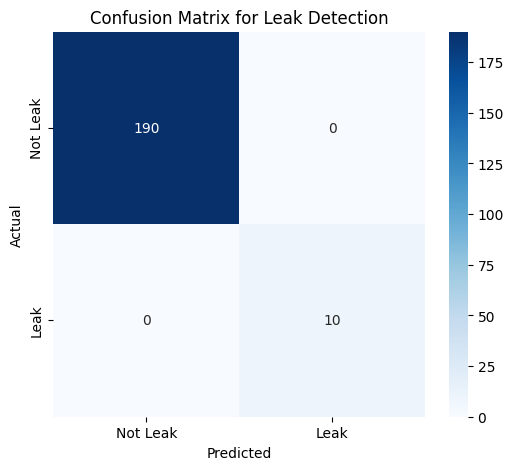

Model saved to /content/drive/MyDrive/DataLeakMonitorProject/leak_detection_model.pkl
Vectorizer saved to /content/drive/MyDrive/DataLeakMonitorProject/tfidf_vectorizer.pkl


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib # For saving/loading models

print("\n--- ML Classification Setup ---")

# Combine rule-based and NER features into the dataset for ML
# For now, we'll use cleaned_post text as the primary feature,
# but you could add 'has_regex_leak' and 'has_ner_entity' as additional features.

X = df['cleaned_post']
y = df['is_leak'] # The target variable: 1 for leak, 0 for not leak

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {len(X_train)}")
print(f"Testing set size: {len(X_test)}")
print(f"Leak samples in training: {y_train.sum()} ({y_train.sum()/len(y_train):.2%})")
print(f"Leak samples in testing: {y_test.sum()} ({y_test.sum()/len(y_test):.2%})")

# Feature Extraction: TF-IDF Vectorizer
# Converts text into numerical feature vectors
tfidf_vectorizer = TfidfVectorizer(max_features=5000) # Limit features to 5000
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print(f"TF-IDF features shape: {X_train_tfidf.shape}")

# Train a Machine Learning Classifier (Logistic Regression is a good starting point)
# Due to class imbalance (few leaks), we use class_weight='balanced'
model = LogisticRegression(class_weight='balanced', solver='liblinear', random_state=42)
model.fit(X_train_tfidf, y_train)

# Evaluate the model
y_pred = model.predict(X_test_tfidf)

print("\n--- Model Evaluation ---")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Leak', 'Leak'], yticklabels=['Not Leak', 'Leak'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Leak Detection')
plt.show()

# Save the trained model and vectorizer
model_path = os.path.join(project_path, 'leak_detection_model.pkl')
vectorizer_path = os.path.join(project_path, 'tfidf_vectorizer.pkl')

joblib.dump(model, model_path)
joblib.dump(tfidf_vectorizer, vectorizer_path)

print(f"Model saved to {model_path}")
print(f"Vectorizer saved to {vectorizer_path}")

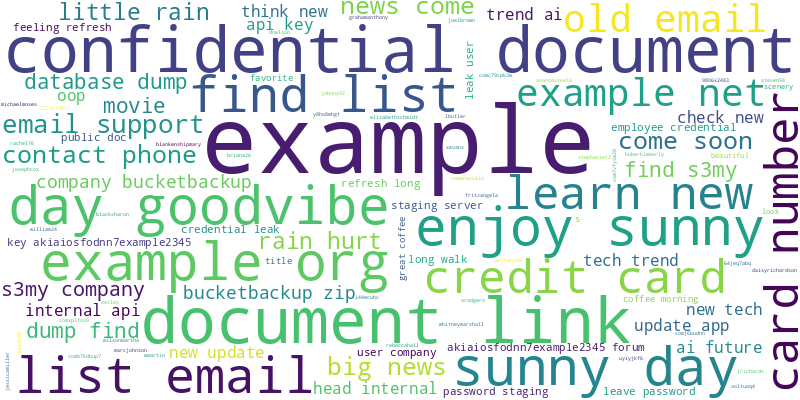

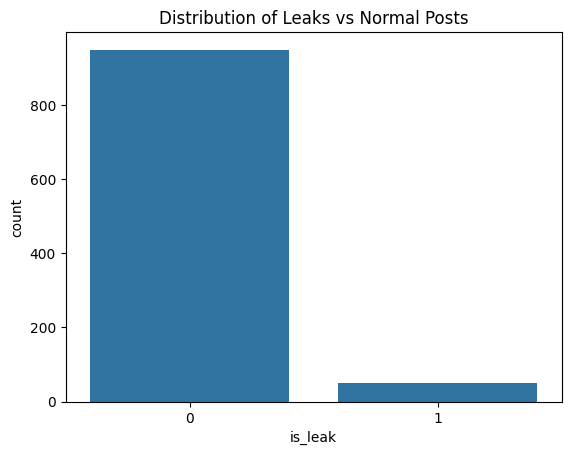

In [ ]:
sns.countplot(x='is_leak', data=df)
plt.title("Distribution of Leaks vs Normal Posts")

# Word cloud for leak terms
from wordcloud import WordCloud
leak_texts = " ".join(df[df['is_leak'] == 1]['cleaned_post'])
WordCloud(width=800, height=400, background_color='white').generate(leak_texts).to_image()


In [ ]:
!pip install streamlit
import streamlit as st

st.title("AI-Powered Data Leak Monitor")
user_input = st.text_area("Enter your post here:")
if st.button("Analyze"):
    result = analyze_post_for_leak(user_input)
    if result['is_leak_detected']:
        st.error("⚠️ Potential Data Leak Detected!")
        st.write(result['details'])
    else:
        st.success("✅ No sensitive data found.")


2025-10-30 08:03:19.896 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-30 08:03:19.901 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-30 08:03:19.902 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-30 08:03:19.904 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-30 08:03:19.906 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-30 08:03:19.908 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-30 08:03:19.911 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-10-30 08:03:19.912 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [ ]:
import joblib
import pandas as pd
import spacy
import re
import os # Ensure os is imported for path handling

# Load the trained model and vectorizer
# (In a real application, these would be loaded once at startup)
model = joblib.load(os.path.join(project_path, 'leak_detection_model.pkl'))
tfidf_vectorizer = joblib.load(os.path.join(project_path, 'tfidf_vectorizer.pkl'))
nlp = spacy.load("en_core_web_sm") # Ensure spaCy model is loaded

def analyze_post_for_leak(post_text):
    """
    Analyzes a single social media post for potential data leaks using
    rule-based (regex), NER, and ML classification.
    """
    results = {
        "original_post": post_text,
        "is_leak_detected": False,
        "detection_methods": [],
        "details": {}
    }

    # 1. Preprocess the text
    cleaned_text = preprocess_text(post_text)
    results['details']['cleaned_text'] = cleaned_text

    # 2. Rule-Based PII Detection (Regex)
    regex_findings = detect_pii_regex(post_text) # Use original text for regex
    if regex_findings:
        results["is_leak_detected"] = True
        results["detection_methods"].append("Regex PII")
        results["details"]["regex_findings"] = regex_findings

    # 3. Named Entity Recognition (NER) - for contextual awareness, not direct leak detection usually
    ner_findings = detect_sensitive_entities(post_text)
    if ner_findings:
        results["details"]["ner_findings"] = ner_findings


    # 4. ML Classification
    # Transform the cleaned text using the trained TF-IDF vectorizer
    text_vectorized = tfidf_vectorizer.transform([cleaned_text])
    ml_prediction = model.predict(text_vectorized)[0] # 0 or 1
    ml_probability = model.predict_proba(text_vectorized)[0][1] # Probability of being a leak

    results["details"]["ml_prediction_score"] = float(ml_probability)
    if ml_prediction == 1 and ml_probability > 0.5: # Only consider ML a "detection" if it's confident
        results["is_leak_detected"] = True
        results["detection_methods"].append(f"ML Classifier (P={ml_probability:.2f})")


    # Final decision: If any method detected a leak, mark it as detected
    if "Regex PII" in results["detection_methods"] or (ml_prediction == 1 and ml_probability > 0.6): # A bit stricter for final decision
        results["is_leak_detected"] = True
    else:
        results["is_leak_detected"] = False


    return results

def send_alert(alert_info):
    """Simulates sending an alert (e.g., email, SMS, Slack)."""
    print("\n!!! --- POTENTIAL DATA LEAK ALERT --- !!!")
    print(f"Detection Time: {pd.Timestamp.now()}")
    print(f"Original Post: {alert_info['original_post']}")
    print(f"Detected by: {', '.join(alert_info['detection_methods'])}")
    if 'regex_findings' in alert_info['details']:
        print(f"Regex Matches: {'; '.join(alert_info['details']['regex_findings'])}")
    print(f"ML Score: {alert_info['details'].get('ml_prediction_score', 'N/A'):.2f}")
    print("Action: Investigate immediately!")
    print("--------------------------------------")

# --- Test the integrated system ---
print("\n--- Testing Integrated Detection ---")

test_posts = [
    "Just sharing my thoughts on AI. Fascinating stuff!",
    "Hey everyone, found this email list: user1@example.com, user2@another.org. Don't share!",
    "My secret password for the test server is 'Pa$$word123!'",
    "Feeling great today!",
    "Got a new phone: 555-123-4567. DM me!", # This might be detected as a phone number
    "Confidential internal doc link: https://docs.google.com/document/d/abcdef1234567890abcdef1234567890"
]

for i, post in enumerate(test_posts):
    print(f"\n--- Analyzing Test Post {i+1} ---")
    analysis_results = analyze_post_for_leak(post)
    print(f"Post: {post}")
    print(f"Leak Detected: {analysis_results['is_leak_detected']}")
    print(f"Methods: {analysis_results['detection_methods']}")
    print(f"Details: {analysis_results['details']}")

    if analysis_results['is_leak_detected']:
        send_alert(analysis_results)


--- Testing Integrated Detection ---

--- Analyzing Test Post 1 ---
Post: Just sharing my thoughts on AI. Fascinating stuff!
Leak Detected: False
Methods: []
Details: {'cleaned_text': 'share thought ai fascinating stuff', 'ner_findings': ['AI (GPE)'], 'ml_prediction_score': 0.24027022014489044}

--- Analyzing Test Post 2 ---
Post: Hey everyone, found this email list: user1@example.com, user2@another.org. Don't share!
Leak Detected: True
Methods: ['Regex PII', 'ML Classifier (P=0.98)']
Details: {'cleaned_text': 'hey find email list user1@example.com user2@another.org not share', 'regex_findings': ['Email Addresses: user1@example.com, user2@another.org'], 'ml_prediction_score': 0.9770090420750648}

!!! --- POTENTIAL DATA LEAK ALERT --- !!!
Detection Time: 2025-10-30 08:03:21.824291
Original Post: Hey everyone, found this email list: user1@example.com, user2@another.org. Don't share!
Detected by: Regex PII, ML Classifier (P=0.98)
Regex Matches: Email Addresses: user1@example.com, user2@a

In [ ]:
!pip install gradio

import gradio as gr

def analyze_and_display(post):
    results = analyze_post_for_leak(post)
    return results['is_leak_detected'], str(results['detection_methods']), str(results['details'])

iface = gr.Interface(
    fn=analyze_and_display,
    inputs=gr.Textbox(lines=3, label="Enter Social Media Post"),
    outputs=["checkbox", "text", "text"],
    title="AI Data Leak Monitor",
    description="Enter a post to get leak detection results powered by Regex, NER, ML and Transformer NLP."
)
iface.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e8ac7841ac246021e4.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip install gradio

import gradio as gr
import json
import base64
from datetime import datetime

def analyze_and_display_enhanced(post):
    """
    Enhanced analysis function that returns detailed results with encryption
    """
    # Analyze the post
    results = analyze_post_for_leak(post)

    # Determine leak status
    is_leak = results['is_leak_detected']
    leak_status = "🚨 LEAK DETECTED" if is_leak else "✅ NO LEAK DETECTED"

    # Get ML probability
    ml_score = results['details'].get('ml_prediction_score', 0)
    probability = f"{ml_score * 100:.2f}%"

    # Get detection methods
    methods = results.get('detection_methods', [])
    methods_str = "\n".join([f"• {method}" for method in methods]) if methods else "None"

    # Identify leak types
    leak_types = []
    regex_findings = results['details'].get('regex_findings', [])
    if regex_findings:
        for finding in regex_findings:
            if 'Email' in finding:
                leak_types.append("📧 Email Address")
            if 'Phone' in finding:
                leak_types.append("📱 Phone Number")
            if 'Password' in finding:
                leak_types.append("🔑 Password")
            if 'Credit Card' in finding:
                leak_types.append("💳 Credit Card")
            if 'API Key' in finding:
                leak_types.append("🔐 API Key")
            if 'IP Address' in finding:
                leak_types.append("🌐 IP Address")
            if 'Document Link' in finding:
                leak_types.append("📄 Confidential Document")

    leak_types_str = "\n".join(leak_types) if leak_types else "No specific PII detected"

    # Build detailed findings
    findings_text = "**Regex Findings:**\n"
    if regex_findings:
        for finding in regex_findings:
            findings_text += f"  • {finding}\n"
    else:
        findings_text += "  None\n"

    findings_text += "\n**NER Findings:**\n"
    ner_findings = results['details'].get('ner_findings', [])
    if ner_findings:
        for finding in ner_findings:
            findings_text += f"  • {finding}\n"
    else:
        findings_text += "  None\n"

    findings_text += f"\n**ML Confidence Score:** {probability}"

    # Generate encryption if leak detected
    encrypted_key = ""
    encrypted_message = ""
    encryption_details = ""

    if is_leak:
        # Generate alert data
        alert_data = generate_alert_data(results)

        # Encrypt the alert
        encrypted_data = encrypt_alert_message(alert_data, project_path + '/public.pem')

        # Get encrypted session key (Base64)
        encrypted_key = base64.b64encode(encrypted_data['encrypted_session_key']).decode()

        # Get encrypted message (Base64)
        encrypted_message = base64.b64encode(encrypted_data['ciphertext']).decode()

        # Encryption details
        encryption_details = f"""
**🔒 ENCRYPTION APPLIED**

**Algorithm:** RSA-2048 + AES-256 (EAX Mode)
**Timestamp:** {encrypted_data['encryption_info']['timestamp']}
**SHA-256 Hash:** {encrypted_data['message_hash'][:32]}...

**Alert ID:** {alert_data['alert_id']}
**Severity:** {alert_data['severity']}

**Recommended Actions:**
"""
        for action in alert_data['recommended_actions']:
            encryption_details += f"  • {action}\n"

        # Save encrypted alert
        alert_file = project_path + f'/encrypted_alert_{alert_data["alert_id"]}.bin'
        with open(alert_file, 'wb') as f:
            f.write(encrypted_data['encrypted_session_key'])
            f.write(encrypted_data['nonce'])
            f.write(encrypted_data['tag'])
            f.write(encrypted_data['ciphertext'])

        encryption_details += f"\n💾 **Saved to:** {alert_file}"

    return (
        leak_status,
        probability,
        leak_types_str,
        methods_str,
        findings_text,
        encrypted_key if is_leak else "N/A - No leak detected",
        encrypted_message if is_leak else "N/A - No leak detected",
        encryption_details if is_leak else "No encryption needed - Post is safe"
    )

# Create enhanced Gradio interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        """
        # 🛡️ AI-Powered Data Leak Detection System
        ### Protect your data with advanced AI detection powered by Regex, NER, ML, and Transformer NLP

        Enter a social media post below to analyze for potential data leaks.
        """
    )

    with gr.Row():
        with gr.Column(scale=1):
            input_text = gr.Textbox(
                lines=5,
                label="📝 Enter Social Media Post",
                placeholder="Type or paste your social media post here..."
            )
            analyze_btn = gr.Button("🔍 Analyze for Leaks", variant="primary", size="lg")

            gr.Markdown("### 💡 Test Examples:")
            gr.Examples(
                examples=[
                    ["Just enjoying a sunny day! #goodvibes"],
                    ["My email is user@company.com and password is Admin123!"],
                    ["Check out this confidential doc: https://docs.google.com/document/d/CONFIDENTIAL123"],
                    ["Contact me at 555-123-4567 for more info!"],
                    ["Our API key is AKIAIOSFODNN7EXAMPLE_2345"]
                ],
                inputs=input_text
            )

    gr.Markdown("---")
    gr.Markdown("## 📊 Analysis Results")

    with gr.Row():
        with gr.Column(scale=1):
            status_output = gr.Textbox(label="🔍 Detection Status", lines=1)
            probability_output = gr.Textbox(label="📈 Leak Probability", lines=1)
            leak_types_output = gr.Textbox(label="🏷️ Leak Types Detected", lines=4)
            methods_output = gr.Textbox(label="🔬 Detection Methods Used", lines=3)

        with gr.Column(scale=1):
            findings_output = gr.Textbox(label="📋 Detailed Findings", lines=12)

    gr.Markdown("---")
    gr.Markdown("## 🔐 Encryption Output (Generated if Leak Detected)")

    with gr.Row():
        with gr.Column():
            encryption_details_output = gr.Textbox(
                label="📄 Encryption Details & Actions",
                lines=12
            )

    with gr.Row():
        with gr.Column():
            encrypted_key_output = gr.Textbox(
                label="🔑 Encrypted Session Key (RSA-2048) - Base64",
                lines=4,
                max_lines=4
            )

        with gr.Column():
            encrypted_message_output = gr.Textbox(
                label="🔒 Encrypted Alert Message (AES-256) - Base64",
                lines=4,
                max_lines=4
            )

    gr.Markdown(
        """
        ---
        ### 🔐 How Encryption Works:
        - **RSA-2048:** Encrypts the AES session key (displayed above)
        - **AES-256:** Encrypts the actual alert message using the session key
        - **SHA-256:** Creates a hash for message integrity verification
        - **Result:** Only someone with the private RSA key can decrypt the alert

        ### 🎯 Detected Leak Types:
        - 📧 Email Addresses
        - 📱 Phone Numbers
        - 🔑 Passwords
        - 💳 Credit Card Numbers
        - 🔐 API Keys
        - 🌐 IP Addresses
        - 📄 Confidential Documents
        """
    )

    # Connect the button to the function
    analyze_btn.click(
        fn=analyze_and_display_enhanced,
        inputs=input_text,
        outputs=[
            status_output,
            probability_output,
            leak_types_output,
            methods_output,
            findings_output,
            encrypted_key_output,
            encrypted_message_output,
            encryption_details_output
        ]
    )

# Launch the interface
demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://6be1486bc572cd7bc2.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
